In [133]:
import torch
import sys
import numpy as np
import matplotlib.pyplot as plt
from utils import list_files
from pathlib import Path
from plot_anm_score import AnmScoreFigData
from sklearn import metrics


In [134]:
machine = 'ToyCar'
# machine = 'fan'

BASEDIR='D:/uni/TER LD/data'

TRAIN_PT_DIR = Path("%s/%s/train"%(BASEDIR, machine))
TEST_PT_DIR = Path("%s/%s/test"%(BASEDIR, machine))


In [135]:
list_train_files = list_files(TRAIN_PT_DIR)
list_test_files = list_files(TEST_PT_DIR)

In [136]:
def load_pt_file(file_path):
    
    relative_path = file_path.relative_to(file_path.parents[2])
    file_name = relative_path.with_suffix(".pt").name
    print(f"file_name: {file_name}")
    data = torch.load(file_path)
    return file_name, data['hidden_states']

In [137]:
f, d = load_pt_file(list_train_files[0])
d.size()

file_name: section_00_source_train_normal_0000_noAttribute.pt


torch.Size([275, 768])

In [138]:
def concatenate_hidden_states(file_paths, reduction='avg'):
    
    output = {'train': {'source': [], 'target': []}, 
              'test': {'source': {'normal': [], 'anomaly': []}, 'target': {'normal': [], 'anomaly': []}}}
    
    for file_path in file_paths:
        file_name, hidden_states = load_pt_file(file_path)
        if reduction == 'avg':
            hidden_states = hidden_states.mean(dim=0, keepdim=True)  # Average over the sequence length dimension
        elif reduction == 'max':
            hidden_states, _ = hidden_states.max(dim=0, keepdim=True)  # Max over the sequence length dimension
        elif reduction == 'std':
            hidden_states = hidden_states.std(dim=0, keepdim=True)  # Std over the sequence length dimension
        # elif reduction == 'none':
        #     hidden_states = hidden_states.unsqueeze(0)  # Add a dummy dimension for concatenation
        print(hidden_states.size())
        # print(file_path)
        if 'train' in file_name:
            if 'source' in file_name:
                output['train']['source'].append(hidden_states)
            elif 'target' in file_name:
                output['train']['target'].append(hidden_states)
        elif 'test' in file_name:
            if 'source' in file_name:
                if 'normal' in file_name:
                    output['test']['source']['normal'].append(hidden_states)
                elif 'anomaly' in file_name:
                    output['test']['source']['anomaly'].append(hidden_states)
            elif 'target' in file_name:
                if 'normal' in file_name:
                    output['test']['target']['normal'].append(hidden_states)
                elif 'anomaly' in file_name:
                    output['test']['target']['anomaly'].append(hidden_states)
    
    # concatenate the lists of tensors into single tensors
    for split in output:
        for category in output[split]:
            if isinstance(output[split][category], dict):
                for subcategory in output[split][category]:
                    output[split][category][subcategory] = torch.cat(output[split][category][subcategory], dim=0)
            else:
                output[split][category] = torch.cat(output[split][category], dim=0)
    return output

In [139]:
avg_states = concatenate_hidden_states(list_train_files + list_test_files, reduction='avg')

file_name: section_00_source_train_normal_0000_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0001_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0002_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0003_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0004_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0005_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0006_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0007_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0008_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0009_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0010_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0011_noAttribute.pt
torch.Size([1, 768])
file

In [140]:
for split in avg_states:
        for category in avg_states[split]:
            if isinstance(avg_states[split][category], dict):
                for subcategory in avg_states[split][category]:
                    print(split, category, subcategory, avg_states[split][category][subcategory].size())
            else:
                print(split, category, avg_states[split][category].size())

train source torch.Size([990, 768])
train target torch.Size([10, 768])
test source normal torch.Size([50, 768])
test source anomaly torch.Size([50, 768])
test target normal torch.Size([50, 768])
test target anomaly torch.Size([50, 768])


In [141]:
train_X = torch.cat([avg_states['train']['source'], avg_states['train']['target']], dim=0)
train_y = torch.cat([torch.zeros(avg_states['train']['source'].size(0)), torch.ones(avg_states['train']['target'].size(0))], dim=0)

train_source_X = avg_states['train']['source']
train_target_X = avg_states['train']['target']

train_source_y = torch.zeros(avg_states['train']['source'].size(0))
train_target_y = torch.ones(avg_states['train']['target'].size(0))

test_source_X = torch.cat([avg_states['test']['source']['normal'], avg_states['test']['source']['anomaly']], dim=0)
test_source_y = torch.cat([torch.zeros(avg_states['test']['source']['normal'].size(0)), torch.ones(avg_states['test']['source']['anomaly'].size(0))], dim=0)    

test_target_X = torch.cat([avg_states['test']['target']['normal'], avg_states['test']['target']['anomaly']], dim=0)
test_target_y = torch.cat([torch.zeros(avg_states['test']['target']['normal'].size(0)), torch.ones(avg_states['test']['target']['anomaly'].size(0))], dim=0)

train_X.size(), train_y.size(), train_source_X.size(), train_source_y.size(), train_target_X.size(), train_target_y.size(), test_source_X.size(), test_source_y.size(), test_target_X.size(), test_target_y.size(), torch.mean(train_X, dim=0), torch.std(train_X, dim=0)

(torch.Size([1000, 768]),
 torch.Size([1000]),
 torch.Size([990, 768]),
 torch.Size([990]),
 torch.Size([10, 768]),
 torch.Size([10]),
 torch.Size([100, 768]),
 torch.Size([100]),
 torch.Size([100, 768]),
 torch.Size([100]),
 tensor([ 6.2107e-01,  2.5724e-02,  5.0057e-02, -9.7057e-02,  7.0744e-02,
         -6.6743e-02,  4.4076e-01, -2.2352e-01, -1.3879e-01,  1.9746e-02,
          1.2982e-01,  4.3672e-01,  1.2240e-01,  1.9581e-01, -2.1957e-01,
          1.0887e-01, -6.7775e-01, -5.5725e-01, -1.9157e-01,  1.8685e-01,
         -1.7266e-01, -8.1788e-01, -2.5893e-01,  2.7444e-01,  2.8151e-01,
         -1.4596e-02,  2.4616e-01,  1.8374e-01, -6.8590e-02, -2.9961e-01,
          1.9572e-01,  1.7118e-02,  7.9673e-02,  1.1603e-01, -3.3683e-01,
         -1.0224e-01,  5.3776e-01, -2.3190e-01, -1.7891e-01,  1.9125e-01,
          5.3098e-01, -5.0965e-01,  1.2230e-01,  1.0207e-01,  2.0171e-01,
          1.1768e-01, -1.6884e-01,  2.9011e-01, -2.3478e-01,  2.6825e-01,
         -8.3318e-02,  3.4187e-01, 

## Standardize the data !

In [142]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# 1. Apprend la moyenne/variance sur le Train et applique la transformation

train_source_X_scaled = scaler.fit_transform(train_source_X.numpy())
test_source_X_scaled = scaler.transform(test_source_X.numpy())
train_target_X_scaled = scaler.transform(train_target_X.numpy())
test_target_X_scaled = scaler.transform(test_target_X.numpy())

train_source_X = torch.from_numpy(train_source_X_scaled).float()
test_source_X = torch.from_numpy(test_source_X_scaled).float()
train_target_X = torch.from_numpy(train_target_X_scaled).float()
test_target_X = torch.from_numpy(test_target_X_scaled).float()

train_source_X.size(), test_source_X.size(), torch.mean(train_source_X, dim=0), torch.std(train_source_X, dim=0)

(torch.Size([990, 768]),
 torch.Size([100, 768]),
 tensor([ 2.0422e-07,  1.1560e-08, -1.1560e-08,  7.0803e-08, -2.3119e-08,
          2.2156e-08, -1.5557e-07, -7.7065e-08,  1.4161e-07, -1.5413e-08,
         -1.1174e-07,  3.9496e-08, -2.6973e-08, -1.2330e-07, -2.6973e-08,
          2.5046e-08, -1.9266e-08, -3.3427e-07,  4.0459e-08, -3.8532e-09,
         -1.9266e-08, -1.6954e-07,  1.6954e-07,  6.9358e-08, -8.4771e-08,
          7.7065e-09, -1.2234e-07,  5.5390e-08,  3.3716e-09, -1.7725e-07,
         -2.4564e-08, -1.1560e-08,  9.6331e-10, -3.9496e-08, -2.4179e-07,
          4.6239e-08,  0.0000e+00,  8.8624e-08, -3.8532e-09,  9.2478e-08,
          9.6331e-09, -4.0459e-08,  1.5413e-08, -1.8303e-08, -1.0404e-07,
          2.4805e-08,  3.2752e-08,  1.4835e-07, -1.3486e-07, -5.5872e-08,
         -1.5413e-08,  1.0404e-07,  6.7432e-09,  3.8532e-09,  3.3716e-08,
          5.7798e-08, -7.7065e-09,  5.7798e-09, -4.6239e-08, -2.3119e-08,
          2.4275e-07,  7.6101e-08, -5.2500e-08, -1.1560e-08, -

# Train: source vs target ?

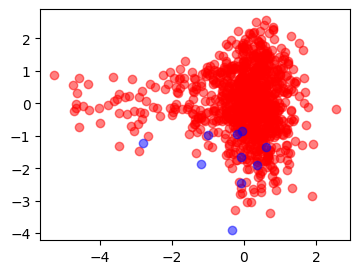

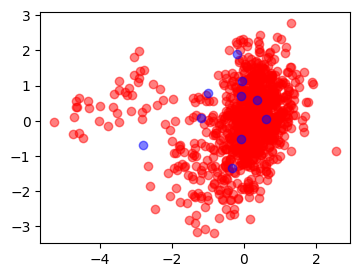

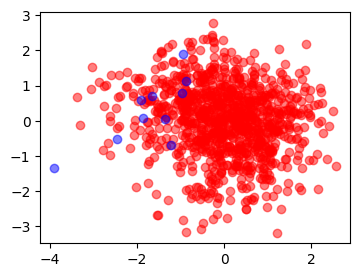

In [143]:
plt.figure(figsize=(4, 3))
plt.scatter(train_source_X[:, 0], train_source_X[:, 1], label='source', c='r', alpha=0.5)
plt.scatter(train_target_X[:, 0], train_target_X[:, 1], label='target', c='b', alpha=0.5)
plt.figure(figsize=(4, 3))
plt.scatter(train_source_X[:, 0], train_source_X[:, 2], label='source', c='r', alpha=0.5)
plt.scatter(train_target_X[:, 0], train_target_X[:, 2], label='target', c='b', alpha=0.5)
plt.figure(figsize=(4, 3))
plt.scatter(train_source_X[:, 1], train_source_X[:, 2], label='source', c='r', alpha=0.5)
plt.scatter(train_target_X[:, 1], train_target_X[:, 2], label='target', c='b', alpha=0.5)

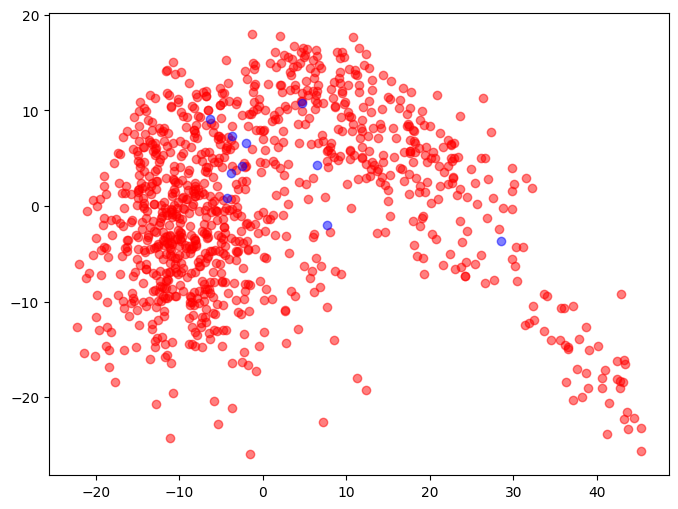

In [144]:
# dimension reduction with PCA for visualization
from sklearn.decomposition import PCA
pca = PCA(n_components=5)
pca.fit(train_source_X.numpy())
train_source_X_pca = pca.transform(train_source_X.numpy())
train_target_X_pca = pca.transform(train_target_X.numpy())
# plot the PCA-reduced data with scatter points colored by source/target label
plt.figure(figsize=(8, 6))
plt.scatter(train_source_X_pca[:, 0], train_source_X_pca[:, 1], label='source', c='r', alpha=0.5)
plt.scatter(train_target_X_pca[:, 0], train_target_X_pca[:, 1], label='target', c='b', alpha=0.5)

---------- Modifs LD -----------

In [145]:
print("Importance de chaque dimensions :")
print(pca.explained_variance_ratio_)
print("\n importance cumulée :")
print(np.cumsum(pca.explained_variance_ratio_))

Importance de chaque dimensions :
[0.2777433  0.1025564  0.0667867  0.05349971 0.03940863]

 importance cumulée :
[0.2777433  0.38029972 0.44708642 0.50058615 0.5399948 ]


In [146]:
print(train_source_X_pca.shape, train_target_X_pca.shape)

(990, 5) (10, 5)


In [147]:
from LD.utils.ld_tools import *
import sys
import os
import copy

dimensions_keept = [0, 1]
points = copy.deepcopy(train_source_X_pca[:, dimensions_keept])
points_target = copy.deepcopy(train_target_X_pca[:, dimensions_keept])

alpha = 3
dist_mat = distance_matrix(points, points)
fermat_dist_mat = fermat_function(dist_mat, alpha=alpha)


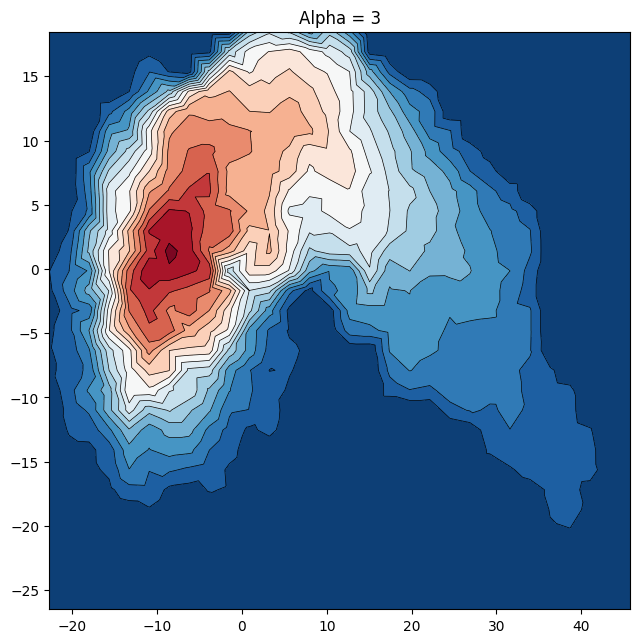

In [148]:

minX1, maxX1, minX2, maxX2 = np.min(points[:,0])-0.5, np.max(points[:,0])+0.5, np.min(points[:,1])-0.5, np.max(points[:,1])+0.5
x1 = np.linspace(minX1, maxX1, 30)
x2 = np.linspace(minX2, maxX2, 30)
X1, X2 = np.meshgrid(x1, x2)
X1 = X1.reshape(-1,)
X2 = X2.reshape(-1,)
points_ext = np.zeros((len(X1),2))
points_ext[:,0] = X1
points_ext[:,1] = X2

lens_depth_ext_fermat = []
for i in range(points_ext.shape[0]):
    dist_array = distance_matrix(points,points_ext[i].reshape((1,-1)))
    dist_ext = fermat_function_ext(fermat_dist_mat, dist_array,alpha)
    lens_depth_ext_fermat += [lens_depth_ext_function(fermat_dist_mat, dist_ext)]

plt.rcParams["figure.figsize"] = (7.5,7.5)
fig, ax = plt.subplots()
ax.tricontour(points_ext[:,0], points_ext[:,1], lens_depth_ext_fermat, levels=20, linewidths=0.5, colors='k')
cntr = ax.tricontourf(points_ext[:,0], points_ext[:,1], lens_depth_ext_fermat, levels=20, cmap="RdBu_r")

# ax.plot(points[:,0], points[:,1], 'ko', ms=3)
# ax.plot(points_target[:,0], points_target[:,1], 'ko', ms=3, color="yellow")

ax.set(xlim=(np.min(points[:,0])-0.5, np.max(points[:,0])+0.5), ylim=(np.min(points[:,1])-0.5, np.max(points[:,1])+0.5))
plt.title(f'Alpha = {alpha}')
plt.show()

-------------------------------------------


c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


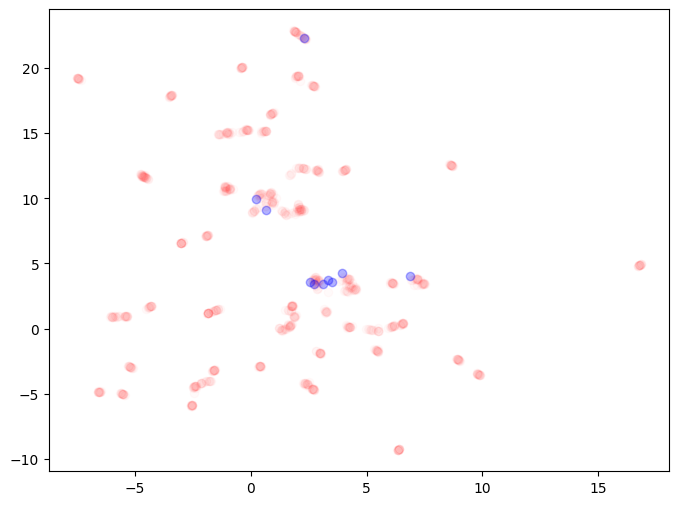

In [149]:
# dimension reduction with umap for visualization
import umap

umap_reducer = umap.UMAP(n_components=2, random_state=0)
umap_reducer.fit(train_source_X.numpy())
train_source_X_umap = umap_reducer.transform(train_source_X.numpy())
train_target_X_umap = umap_reducer.transform(train_target_X.numpy())
plt.figure(figsize=(8, 6))
plt.scatter(train_source_X_umap[:, 0], train_source_X_umap[:, 1], label='source', c='r', alpha=0.02)
plt.scatter(train_target_X_umap[:, 0], train_target_X_umap[:, 1], label='target', c='b', alpha=0.3)

In [150]:
test_source_X_umap = umap_reducer.transform(test_source_X.numpy())

In [151]:
dimensions_keept2 = [0, 1]
points = copy.deepcopy(train_source_X_umap[:, dimensions_keept2])
points_target = copy.deepcopy(train_target_X_umap[:, dimensions_keept2])

alpha2 = 7
dist_mat = distance_matrix(points, points)
fermat_dist_mat = fermat_function(dist_mat, alpha=alpha2)
points_test = copy.deepcopy(test_source_X_umap[:, dimensions_keept2])

C:\Users\PC\AppData\Local\Temp\ipykernel_28300\1923217084.py:25: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ko" (-> color='k'). The keyword argument will take precedence.
  ax.plot(points_test[:,0], points_test[:,1], 'ko', ms=3, color="lightgreen", label='test')


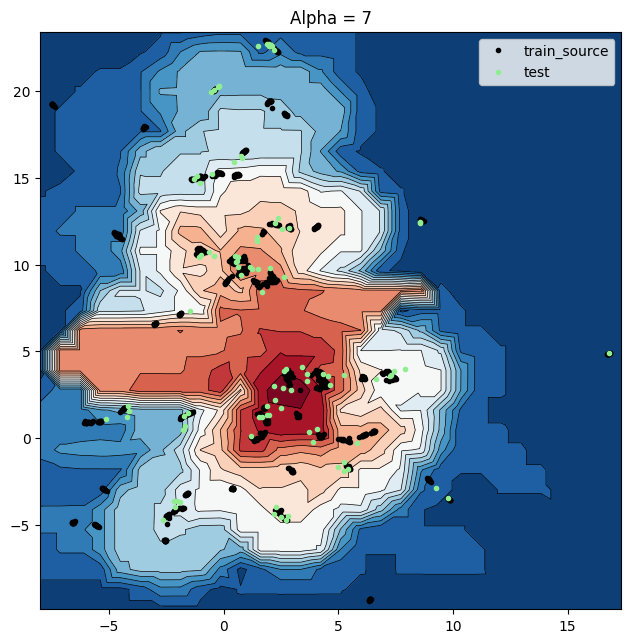

In [152]:
minX1, maxX1, minX2, maxX2 = np.min(points[:,0])-0.5, np.max(points[:,0])+0.5, np.min(points[:,1])-0.5, np.max(points[:,1])+0.5
x1 = np.linspace(minX1, maxX1, 30)
x2 = np.linspace(minX2, maxX2, 30)
X1, X2 = np.meshgrid(x1, x2)
X1 = X1.reshape(-1,)
X2 = X2.reshape(-1,)
points_ext = np.zeros((len(X1),2))
points_ext[:,0] = X1
points_ext[:,1] = X2

lens_depth_ext_fermat = []
for i in range(points_ext.shape[0]):
    dist_array = distance_matrix(points,points_ext[i].reshape((1,-1)))
    dist_ext = fermat_function_ext(fermat_dist_mat, dist_array,alpha2)
    lens_depth_ext_fermat += [lens_depth_ext_function(fermat_dist_mat, dist_ext)]

plt.rcParams["figure.figsize"] = (7.5,7.5)
fig, ax = plt.subplots()
ax.tricontour(points_ext[:,0], points_ext[:,1], lens_depth_ext_fermat, levels=20, linewidths=0.5, colors='k')
cntr = ax.tricontourf(points_ext[:,0], points_ext[:,1], lens_depth_ext_fermat, levels=20, cmap="RdBu_r")

ax.plot(points[:,0], points[:,1], 'ko', ms=3, label='train_source')
# ax.plot(points_target[:,0], points_target[:,1], 'ko', ms=3, color="yellow", label='train_target')

ax.plot(points_test[:,0], points_test[:,1], 'ko', ms=3, color="lightgreen", label='test')

ax.set(xlim=(np.min(points[:,0])-0.5, np.max(points[:,0])+0.5), ylim=(np.min(points[:,1])-0.5, np.max(points[:,1])+0.5))
plt.title(f'Alpha = {alpha2}')
plt.legend()
plt.show()

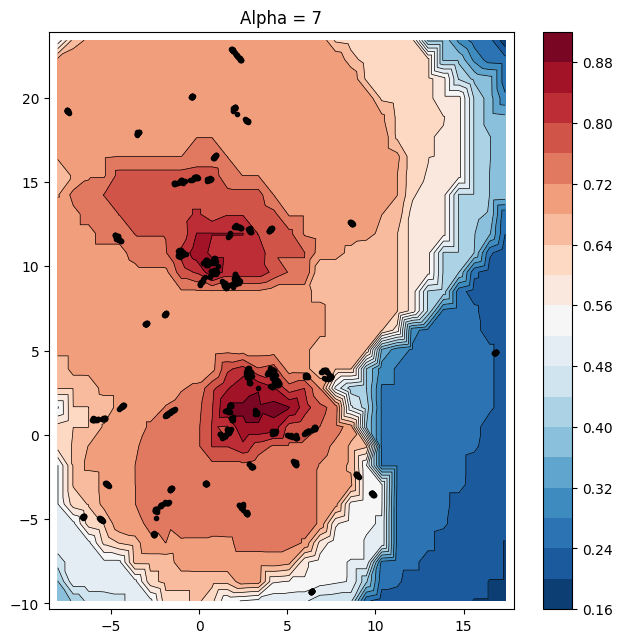

In [153]:
from sklearn.cluster import KMeans



kmeans = KMeans(n_clusters=2, random_state=0).fit(train_source_X_umap)
cluster1 = train_source_X_umap[kmeans.labels_ == 0]
cluster2 = train_source_X_umap[kmeans.labels_ == 1]
#cluster3 = train_source_X_umap[kmeans.labels_ == 2]
#cluster4 = train_source_X_umap[kmeans.labels_ == 3]
#cluster5 = train_source_X_umap[kmeans.labels_ == 4]

list_clusters = [cluster1,cluster2]
list_lens_depth_ext_fermat = []
for j in range(len(list_clusters)):
    dist_mat = distance_matrix(list_clusters[j],list_clusters[j])
    fermat_dist_mat = fermat_function(dist_mat,alpha=alpha2)
    lens_depth_ext_fermat = []
    for i in range(points_ext.shape[0]):
        dist_array = distance_matrix(list_clusters[j],points_ext[i].reshape((1,-1)))
        dist_ext = fermat_function_ext(fermat_dist_mat, dist_array)
        lens_depth_ext_fermat += [lens_depth_ext_function(fermat_dist_mat, dist_ext)]
    list_lens_depth_ext_fermat += [np.array(lens_depth_ext_fermat)]
list_lens_depth_ext_fermat = np.array(list_lens_depth_ext_fermat)
lens_depth_ext_fermat_seperate = np.max(list_lens_depth_ext_fermat, axis=0)
plt.rcParams["figure.figsize"] = (7.5,7.5)
fig, ax = plt.subplots()
ax.tricontour(points_ext[:,0], points_ext[:,1], lens_depth_ext_fermat_seperate, levels=20, linewidths=0.5, colors='k')
cntr = ax.tricontourf(points_ext[:,0], points_ext[:,1], lens_depth_ext_fermat_seperate, levels=20, cmap="RdBu_r")
fig.colorbar(cntr, ax=ax)
#ax.plot(X_grid[:,0], X_grid[:,1], 'ko', ms=1, color="white")
ax.plot(points[:,0], points[:,1], 'ko', ms=3)
ax.set(xlim=(np.min(points[:,0])-1, np.max(points[:,0])+1), ylim=(np.min(points[:,1])-1, np.max(points[:,1])+1))
plt.title(f'Alpha = {alpha2}')
plt.show()



In [163]:
points = copy.deepcopy(train_source_X)
points_target = copy.deepcopy(train_target_X)

alpha2 = 7
dist_mat = distance_matrix(points, points)
fermat_dist_mat = fermat_function(dist_mat, alpha=alpha2)
points_test = copy.deepcopy(test_source_X)

In [175]:
print(points.shape)
print(points_test.shape)
print(test_source_X.shape)
print(test_source_y.shape)
print(test_source_y)

torch.Size([990, 768])
torch.Size([100, 768])
torch.Size([100, 768])
torch.Size([100])
tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


In [165]:
lens_depth_ext_fermat = []
for i in range(points_test.shape[0]):
    dist_array = distance_matrix(points,points_test[i].reshape((1,-1)))
    dist_ext = fermat_function_ext(fermat_dist_mat, dist_array,alpha2)
    lens_depth_ext_fermat += [lens_depth_ext_function(fermat_dist_mat, dist_ext)]


In [167]:
print(lens_depth_ext_fermat)
print(min(lens_depth_ext_fermat), max(lens_depth_ext_fermat))

[np.float64(0.00011643227012286669), np.float64(0.2411598288241362), np.float64(0.02922041445802821), np.float64(0.31688165783211286), np.float64(0.35356803627784417), np.float64(0.3207055387035165), np.float64(0.3521299956082565), np.float64(0.528132691934512), np.float64(0.3909346243016617), np.float64(0.34259889082942674), np.float64(0.588334303602251), np.float64(0.03374901696438602), np.float64(0.35195228319596367), np.float64(0.0347580966387842), np.float64(0.0006904229351145428), np.float64(0.027958043529327653), np.float64(0.003021111008977541), np.float64(0.002708582283910899), np.float64(0.02779667248828017), np.float64(0.0018036788512016014), np.float64(0.10150034214746045), np.float64(0.18034950107750916), np.float64(0.41934614088304684), np.float64(0.03932959524466097), np.float64(0.06830897447682079), np.float64(0.018768064875243844), np.float64(0.4192909887550939), np.float64(0.45817323896191436), np.float64(0.4734667197761232), np.float64(6.536548498125849e-05), np.floa

In [196]:
seuil = 0.35
y_pred = (np.array(lens_depth_ext_fermat) > seuil).astype(int)
print(y_pred)
accuracy = metrics.accuracy_score(test_source_y.numpy(), y_pred)
print(accuracy)

[0 0 0 0 1 0 1 1 1 0 1 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 1 1 0 0 0 0 1 0 0 0
 1 0 0 0 0 1 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]
0.37


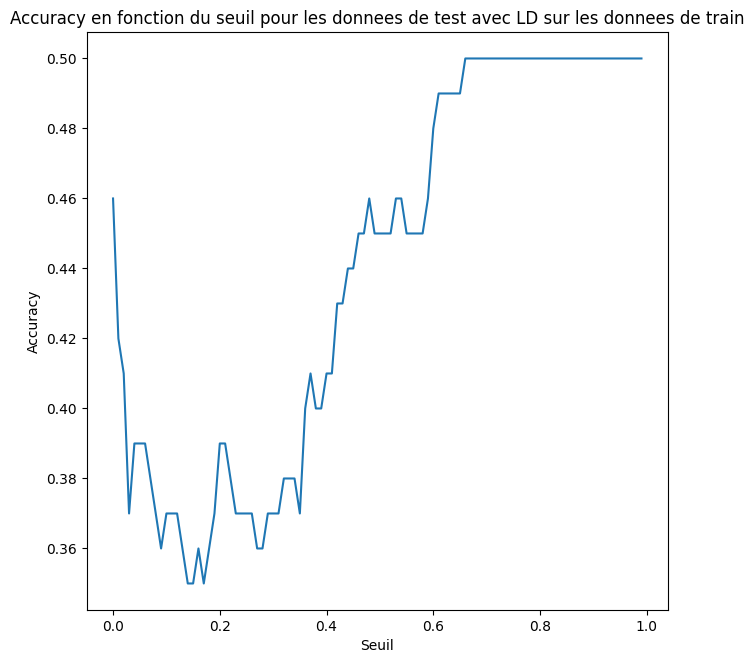

In [ ]:
acc_list = []
for i in range(100):
    seuil = i/100
    y_pred = (np.array(lens_depth_ext_fermat) > seuil).astype(int)
    acc_list.append(metrics.accuracy_score(test_source_y.numpy(), y_pred))
    

plt.plot(np.arange(100)/100, acc_list)
plt.xlabel("Seuil")
plt.ylabel("Accuracy")
plt.title("Accuracy en fonction du seuil pour les donnees de test avec LD sur les donnees de train")
plt.show()

# Test source: normal vs anomaly

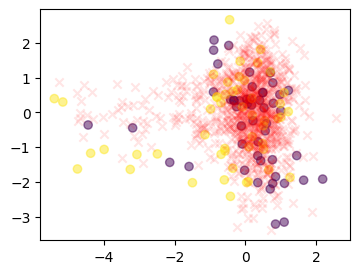

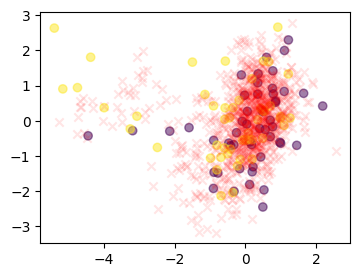

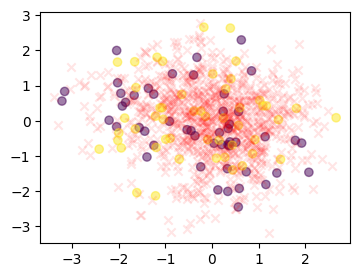

In [116]:
plt.figure(figsize=(4, 3))
plt.scatter(test_source_X[:, 0], test_source_X[:, 1], label='source', c=test_source_y.numpy(), alpha=0.5)
plt.scatter(train_source_X[:, 0], train_source_X[:, 1], label='source', color='red', alpha=0.1, marker='x')
plt.figure(figsize=(4, 3))
plt.scatter(test_source_X[:, 0], test_source_X[:, 2], label='source', c=test_source_y.numpy(), alpha=0.5)
plt.scatter(train_source_X[:, 0], train_source_X[:, 2], label='source', color='red', alpha=0.1, marker='x')
plt.figure(figsize=(4, 3))
plt.scatter(test_source_X[:, 1], test_source_X[:, 2], label='source', c=test_source_y.numpy(), alpha=0.5)
plt.scatter(train_source_X[:, 1], train_source_X[:, 2], label='source', color='red', alpha=0.1, marker='x')

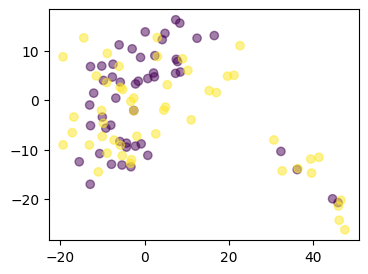

In [117]:
# dimension reduction with PCA for visualization
pca = PCA(n_components=2)
pca.fit(train_source_X.numpy())
test_source_X_pca = pca.transform(test_source_X.numpy())
# plot the PCA-reduced data with scatter points colored by normal/anomaly label
plt.figure(figsize=(4, 3))
plt.scatter(test_source_X_pca[:, 0], test_source_X_pca[:, 1], label='source', c=test_source_y.numpy(), alpha=0.5)

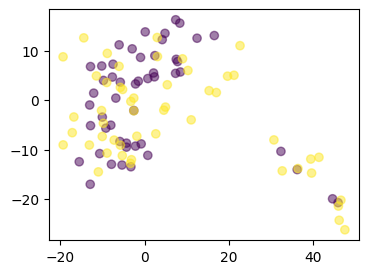

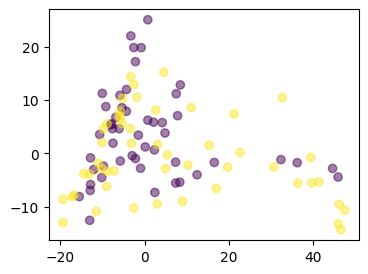

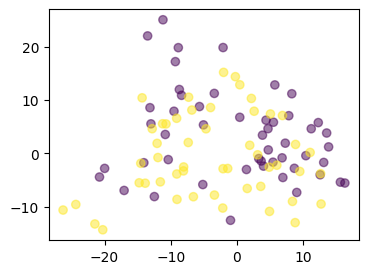

In [118]:
# dimension reduction with PCA for visualization
pca = PCA(n_components=3)
pca.fit(train_source_X.numpy())
test_source_X_pca = pca.transform(test_source_X.numpy())
# plot the PCA-reduced data with scatter points colored by normal/anomaly label
plt.figure(figsize=(4, 3))
plt.scatter(test_source_X_pca[:, 0], test_source_X_pca[:, 1], label='source', c=test_source_y.numpy(), alpha=0.5)
plt.figure(figsize=(4, 3))
plt.scatter(test_source_X_pca[:, 0], test_source_X_pca[:, 2], label='source', c=test_source_y.numpy(), alpha=0.5)
plt.figure(figsize=(4, 3))
plt.scatter(test_source_X_pca[:, 1], test_source_X_pca[:, 2], label='source', c=test_source_y.numpy(), alpha=0.5)


c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


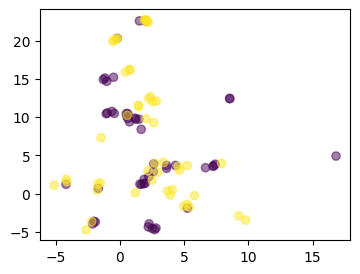

In [119]:
umap_reducer = umap.UMAP(n_components=2, random_state=0)
umap_reducer.fit(train_source_X.numpy())
test_source_X_umap = umap_reducer.transform(test_source_X.numpy())
plt.figure(figsize=(4, 3))
plt.scatter(test_source_X_umap[:, 0], test_source_X_umap[:, 1], label='source', c=test_source_y.numpy(), alpha=0.5)


c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


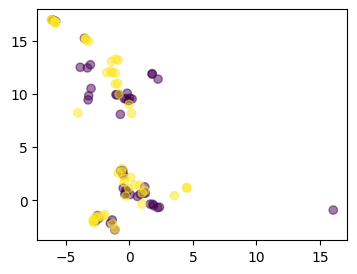

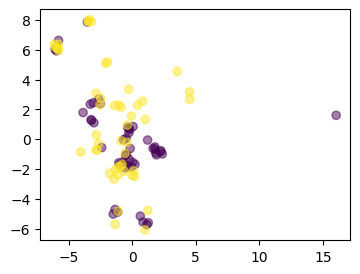

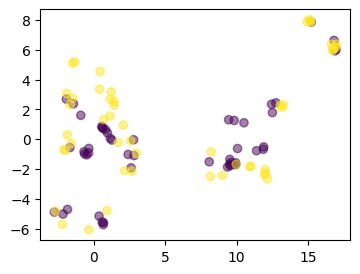

In [120]:
# dimension reduction with umap for visualization
umap_reducer = umap.UMAP(n_components=3, random_state=0)
umap_reducer.fit(train_source_X.numpy())
test_source_X_umap = umap_reducer.transform(test_source_X.numpy())
plt.figure(figsize=(4, 3))
plt.scatter(test_source_X_umap[:, 0], test_source_X_umap[:, 1], label='source', c=test_source_y.numpy(), alpha=0.5)
plt.figure(figsize=(4, 3))
plt.scatter(test_source_X_umap[:, 0], test_source_X_umap[:, 2], label='source', c=test_source_y.numpy(), alpha=0.5)
plt.figure(figsize=(4, 3))
plt.scatter(test_source_X_umap[:, 1], test_source_X_umap[:, 2], label='source', c=test_source_y.numpy(), alpha=0.5)


# Test target: normal vs anomaly

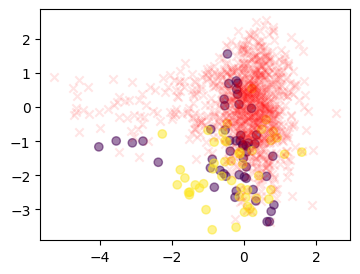

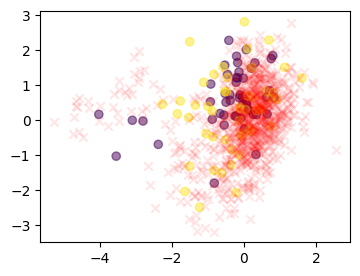

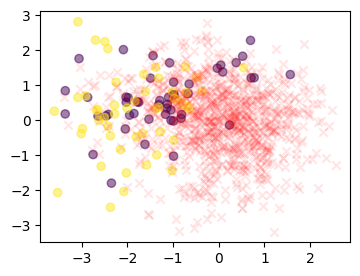

In [121]:
plt.figure(figsize=(4, 3))
plt.scatter(test_target_X[:, 0], test_target_X[:, 1], label='target', c=test_target_y.numpy(), alpha=0.5)
plt.scatter(train_source_X[:, 0], train_source_X[:, 1], label='source', color='red', alpha=0.1, marker='x')
plt.figure(figsize=(4, 3))
plt.scatter(test_target_X[:, 0], test_target_X[:, 2], label='target', c=test_target_y.numpy(), alpha=0.5)
plt.scatter(train_source_X[:, 0], train_source_X[:, 2], label='source', color='red', alpha=0.1, marker='x')
plt.figure(figsize=(4, 3))
plt.scatter(test_target_X[:, 1], test_target_X[:, 2], label='target', c=test_target_y.numpy(), alpha=0.5)
plt.scatter(train_source_X[:, 1], train_source_X[:, 2], label='source', color='red', alpha=0.1, marker='x')

c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:2462: UserWarning: n_neighbors is larger than the dataset size; truncating to X.shape[0] - 1
  warn(


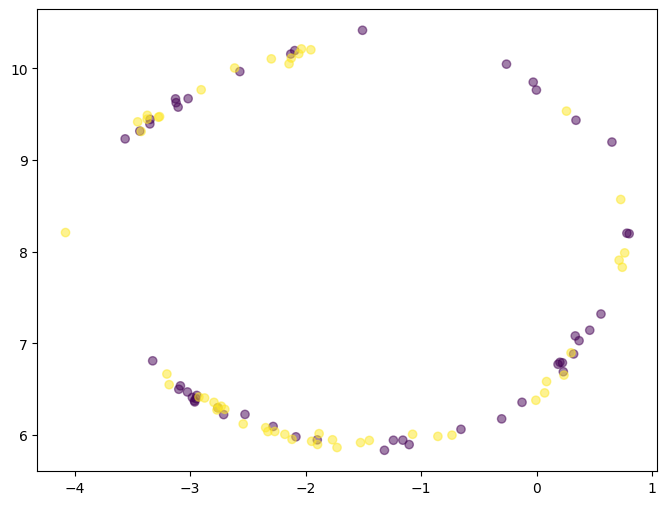

In [122]:
umap_reducer = umap.UMAP(n_components=2, random_state=0)
umap_reducer.fit(train_target_X.numpy())
test_target_X_umap = umap_reducer.transform(test_target_X.numpy())
plt.figure(figsize=(8, 6))
plt.scatter(test_target_X_umap[:, 0], test_target_X_umap[:, 1], label='target', c=test_target_y.numpy(), alpha=0.5)

c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:2462: UserWarning: n_neighbors is larger than the dataset size; truncating to X.shape[0] - 1
  warn(


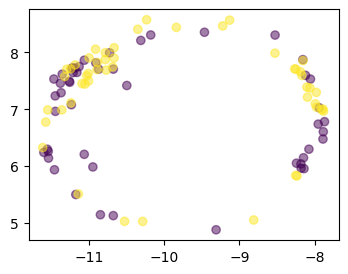

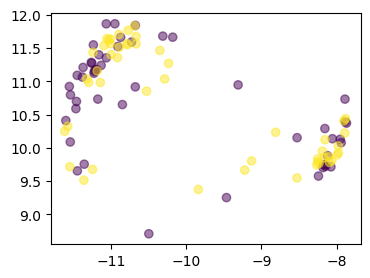

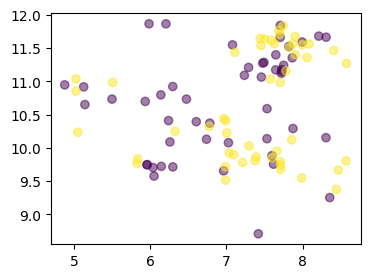

In [123]:
# dimension reduction with umap for visualization
umap_reducer = umap.UMAP(n_components=3, random_state=0)
umap_reducer.fit(train_target_X.numpy())
test_target_X_umap = umap_reducer.transform(test_target_X.numpy())
plt.figure(figsize=(4, 3))
plt.scatter(test_target_X_umap[:, 0], test_target_X_umap[:, 1], label='target', c=test_target_y.numpy(), alpha=0.5)
plt.figure(figsize=(4, 3))
plt.scatter(test_target_X_umap[:, 0], test_target_X_umap[:, 2], label='target', c=test_target_y.numpy(), alpha=0.5)
plt.figure(figsize=(4, 3))
plt.scatter(test_target_X_umap[:, 1], test_target_X_umap[:, 2], label='target', c=test_target_y.numpy(), alpha=0.5)


# Classifier normal/anomaly

In [124]:
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

class my_classifier(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, output_dim=1):
        super(my_classifier, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, output_dim)
    
    def forward(self, x):
        out = torch.relu(self.fc1(x))
        out = self.fc2(out)
        return out
    

class linear_probe(nn.Module):
    def __init__(self, input_dim, output_dim=1):
        super(linear_probe, self).__init__()
        self.fc = nn.Linear(input_dim, output_dim)
    
    def forward(self, x):
        out = self.fc(x)
        return out

In [125]:
# train on the source domain and test on the target domain
test_source_dataset = TensorDataset(test_source_X, test_source_y)
test_source_loader = DataLoader(test_source_dataset, batch_size=16, shuffle=True)
test_target_dataset = TensorDataset(test_target_X, test_target_y)
test_target_loader = DataLoader(test_target_dataset, batch_size=16, shuffle=False)


In [126]:
def test_model(model, data_loader):
    model.eval()
    all_probs = []
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            outputs = model(X_batch)
            probs = torch.sigmoid(outputs).squeeze()
            preds = (torch.sigmoid(outputs) > 0.5).float().squeeze()
            all_probs.append(probs.cpu())
            all_preds.append(preds.cpu())
            all_labels.append(y_batch.cpu())
    return torch.cat(all_probs), torch.cat(all_preds), torch.cat(all_labels)

In [127]:
model = my_classifier(input_dim=train_X.size(1))
# model = linear_probe(input_dim=train_X.size(1))
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

running_loss = 0.0
nb_epochs = 50


accuracies = {'source': [], 'target': []}

for epoch in range(nb_epochs):
    model.train()
    for i, (inputs, labels) in enumerate(test_source_loader):
        # print(i, labels)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs.squeeze(), labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
    
    print(f"Epoch {epoch+1}, Loss: {running_loss/(i+1):.4f}")
    running_loss = 0.0
    
    # evaluate on the source domain (== training data...)
    all_probs, all_preds, all_labels = test_model(model, test_source_loader)
    accuracy = (all_preds == all_labels).float().mean().item()
    accuracies['source'].append(accuracy)
    print(f"  Source/ Training Domain Accuracy: {accuracy:.4f}")

    # evaluate on the target domain
    all_probs, all_preds, all_labels = test_model(model, test_target_loader)
    accuracy = (all_preds == all_labels).float().mean().item()
    accuracies['target'].append(accuracy)
    print(f"  Target Domain Accuracy: {accuracy:.4f}")

Epoch 1, Loss: 0.6267
  Source/ Training Domain Accuracy: 0.9200
  Target Domain Accuracy: 0.5200
Epoch 2, Loss: 0.4261
  Source/ Training Domain Accuracy: 0.9200
  Target Domain Accuracy: 0.4900
Epoch 3, Loss: 0.3092
  Source/ Training Domain Accuracy: 0.9600
  Target Domain Accuracy: 0.4800
Epoch 4, Loss: 0.2044
  Source/ Training Domain Accuracy: 0.9800
  Target Domain Accuracy: 0.4900
Epoch 5, Loss: 0.1448
  Source/ Training Domain Accuracy: 1.0000
  Target Domain Accuracy: 0.4800
Epoch 6, Loss: 0.0979
  Source/ Training Domain Accuracy: 1.0000
  Target Domain Accuracy: 0.4700
Epoch 7, Loss: 0.0686
  Source/ Training Domain Accuracy: 1.0000
  Target Domain Accuracy: 0.4800
Epoch 8, Loss: 0.0525
  Source/ Training Domain Accuracy: 1.0000
  Target Domain Accuracy: 0.4700
Epoch 9, Loss: 0.0372
  Source/ Training Domain Accuracy: 1.0000
  Target Domain Accuracy: 0.4700
Epoch 10, Loss: 0.0273
  Source/ Training Domain Accuracy: 1.0000
  Target Domain Accuracy: 0.4700
Epoch 11, Loss: 0.0

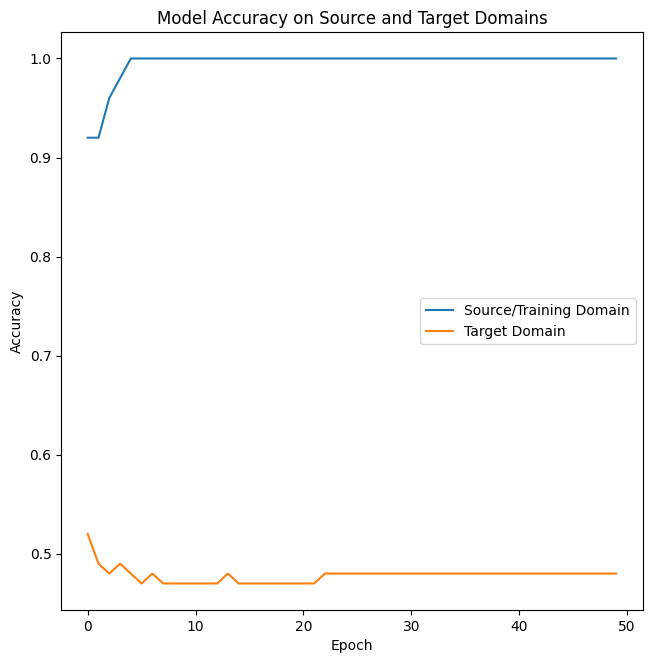

In [128]:
plt.plot(accuracies['source'], label='Source/Training Domain')
plt.plot(accuracies['target'], label='Target Domain')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Model Accuracy on Source and Target Domains')
plt.legend()
plt.show()